### Задачи к Лекции 3

__Исходные данные__ 

Дан файл **"mlbootcamp5_train.csv"**. В нем содержатся данные об опросе 70000 пациентов с целью определения наличия заболеваний сердечно-сосудистой системы (ССЗ). Данные в файле промаркированы и если у человека имееются ССЗ, то значение **cardio** будет равно 1, в противном случае - 0. Описание и значения полей представлены во второй лекции.

__Загрузка файла__

In [2]:
%matplotlib inline
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from matplotlib import pyplot as plt
import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv("C:\\Users\\akush\\Downloads\\Telegram Desktop\\mlbootcamp5_train.csv", 
                 sep=";", 
                 index_col="id")
# Делаем one-hot кодирование
chol = pd.get_dummies(df["cholesterol"], prefix="chol")
gluc = pd.get_dummies(df["gluc"], prefix="gluc")
df = pd.concat([df, chol, gluc], axis=1)

# Делаем пол бинарным признаком
df["gender_bin"] = df["gender"].map({1: 0, 2: 1})
df.head()

,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,chol_1,chol_2,chol_3,gluc_1,gluc_2,gluc_3,gender_bin
id,,,,,,,,,,,,,,,,,,,
0,18393,2,168,62.0,110,80,1,1,0,0,1,0,1,0,0,1,0,0,1
1,20228,1,156,85.0,140,90,3,1,0,0,1,1,0,0,1,1,0,0,0
2,18857,1,165,64.0,130,70,3,1,0,0,0,1,0,0,1,1,0,0,0
3,17623,2,169,82.0,150,100,1,1,0,0,1,1,1,0,0,1,0,0,1
4,17474,1,156,56.0,100,60,1,1,0,0,0,0,1,0,0,1,0,0,0


## Классы в Python

Нередко, возникает необходимость создания объектов с каким-нибудь внутренним поведением и состоянием. Примерами таких объектов являются классификаторы sklearn, массивы numpy и много другое. Такой объект можно объявить с помощью ключевого слова **class**

```python
class SomeObject:
    def __init__(self, depth):
        self.a = depth
        self.target = None
        
    def fit(self, data, target):
        self.target = data
        # magic
        return 
    
    def predict(self, data):
        return self.target    
```

После этого в коде можно будет создать экземпляр данного класса
```python
a = SomeObject(depth=5)
a.fit(data, target)
a.predict(data)
```

## Задачи

**1. В sklearn на данный момент отсутствует функционал для построения деревьев решений из категориальных данных, поэтому его нужно сделать самостоятельно и проверить его работу. Что нужно сделать:**

* __создать классификатор используя только pandas, numpy и scipy. Необходимо его сделать самому, используя исключительно только numpy, pandas и scipy (запрещено использовать sklearn и прочие библиотеки). Напоминаю, что для категориальных данных операция < или > не имеют смысла (использовать только != и ==). Гиперпараметром данного классификатора должна быть максимальная глубина дерева.__
* __Проверить работу данного классификатора на наборе ("gender", "cholesterol", "gluc").__
* __С помощью кросс-валидации найти оптимальную глубину этого дерева. Для вашего классификатора GridSearchCV не подойдет, придется это сделать также самостоятельно.__
* __Нарисовать полученное дерево (я должен понять, как и откуда вы его нарисовали).__

Алгоритм работы классификатора:
 1. Перебираем все возможные признаки и смотрим либо неопределенность Джини, либо прирост информации. Это даст критерий разбиения в виде "признак == значение"
 2. Если выборка полученная при разбиении состоит из объектов одного класса (соответсвует нулевой энтропии), то данный лист просто возвращает значение этого класса.
 3. В противном случае, образуется новый узел и для него начинаем с пункта 1.
 4. Если достигли максимальной глубины, то вместа узла создаем лист, который возвращает самое вероятное значение.
 
__Замечание:__ в этой задаче не нужно использовать onehot-кодирование.

In [1]:
#импортируем библиотеки
import pandas as pd
import numpy as np
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

In [3]:
#выбираем только необходимые для работу столбцы из датафрейма. Делим их на признаки и целевую переменную
df=df[['chol_1','chol_2','chol_3','gluc_1','gluc_2','gluc_3','gender_bin', 'cardio']]
features = df[['chol_1','chol_2','chol_3','gluc_1','gluc_2','gluc_3','gender_bin']]
target = df[['cardio']]

In [4]:
#создаем функцию для кроссвалидаци
def validation(features, target, max_depth):#на вход - признаки, целевая переменная, максимальная глубина дерева
    accs = [] #точности классификаторов 
    for i in range(1,10): #проверяем классификатор на 10 разных наборах
        #создаем наборы для теста и обучения, каждую итерацию разные 
        features_train, features_val, target_train, target_val = train_test_split(
        features, target, test_size=0.3, shuffle=True, random_state=i
        )
        #проверяем классификатор
        mytree = DecisionTreeClassifier(max_depth=max_depth)
        mytree.fit(features_train, target_train)
        #оцениваем точность и добавляем в список
        acc = mytree.score(features_val, target_val)
        accs.append(acc)
    
    return np.mean(accs) #возвращаем среднюю точность при заданной глубине дерева

In [5]:
max_depths = range(1, 11) #проверим глубины дерева от 1 до 10
accs = []
for a in max_depths:
    acc = validation(features, target, a)
    accs.append(acc)
    print(a, '=', acc)
depth = max_depths[np.argmax(accs)]
print("глубина =", depth, "\n acc=", max(accs))

1 = 0.5882010582010583
2 = 0.5908042328042328
3 = 0.5908042328042328
4 = 0.5906296296296296
5 = 0.5906296296296296
6 = 0.5906296296296296
7 = 0.5906296296296296
8 = 0.5906296296296296
9 = 0.5906296296296296
10 = 0.5906296296296296
глубина = 2 
 acc= 0.5908042328042328


In [6]:
features_train, features_val, target_train, target_val = train_test_split(
        features, target, test_size=0.3, shuffle=True, random_state=42
        )

mytree = DecisionTreeClassifier(max_depth=depth) #создаем классификатор
mytree.fit(features_train, target_train)
acc = mytree.score(features_val, target_val)
print(acc)

0.5893809523809523


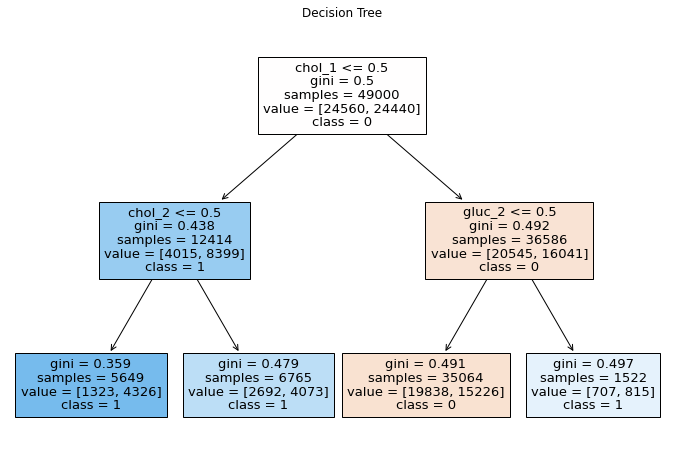

In [7]:
#визуализация

plt.figure(figsize=(12, 8))
plot_tree(mytree, filled=True, feature_names=features.columns, class_names=['0', '1'])
plt.title("Decision Tree")
plt.show()

**Комментарии:** Ваши комментарии здесь.